In [ ]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -------- ------------------------------- 2.1/9.5 MB 12.2 MB/s eta 0:00:01
   --------------------------- ------------ 6.6/9.5 MB 15.8 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 15.0 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   --------------- ------------------------ 5.0/12.7 MB 23.5 MB/s eta 0:00:01
   ---------------------------- ----------- 9.2/12.7 MB 21.1 MB/s eta 0:00:01
   ---------------------------------------  12.6/12.7 MB 20.6 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 18.5 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 13.2 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# each point is length, width, type (0, 1)

data = [[3,   1.5, 1],
        [2,   1,   0],
        [4,   1.5, 1],
        [3,   1,   0],
        [3.5, .5,  1],
        [2,   .5,  0],
        [5.5,  1,  1],
        [1,    1,  0]]

mystery_flower = [4.5, 1]

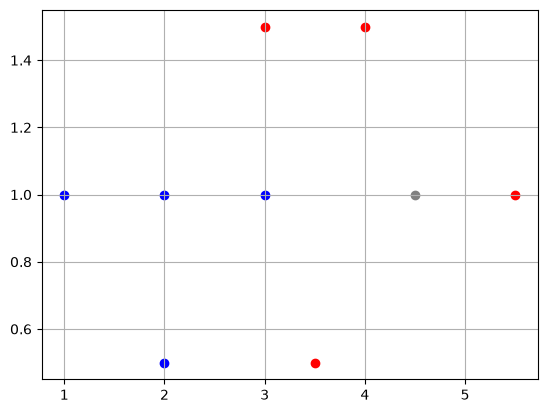

In [5]:
# scatter plot them
def vis_data():
    plt.grid()

    for i in range(len(data)):
        c = 'r'
        if data[i][2] == 0:
            c = 'b'
        plt.scatter([data[i][0]], [data[i][1]], c=c)

    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')
    plt.show()

vis_data()

In [6]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [7]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

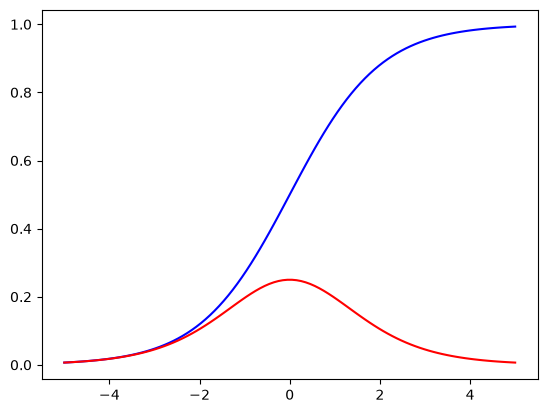

In [8]:
X = np.linspace(-5, 5, 100)
plt.figure()
plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red
plt.show()

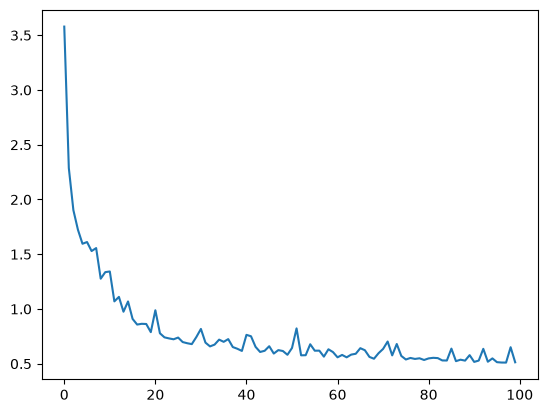

In [9]:
# train

def train():
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()
    
    iterations = 10000
    learning_rate = 0.1
    costs = [] # keep costs during training, see if they go down
    
    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]
        
        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction
        
        target = point[2]
        
        # cost for current random point
        cost = np.square(pred - target)
        
        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)
        
        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)
        
        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1
        
        dcost_dz = dcost_dpred * dpred_dz
        
        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db
        
        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db
        
    return costs, w1, w2, b
        
costs, w1, w2, b = train()

fig = plt.plot(costs)
plt.show()

In [10]:
# predict what the myster flower is!

z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.9761777175227976
close to 0 -> blue, close to 1 -> red


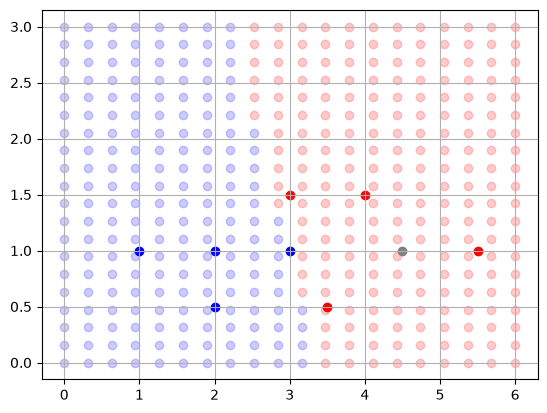

In [11]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)
        
# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()

### Exercise: experiment with learning rate and number of iterations

Compare learning rates such as `0.1` and `0.001`, and reduce iterations from `10000` down to ~`100`-`150`. Observe convergence speed and the shape of the cost curve.


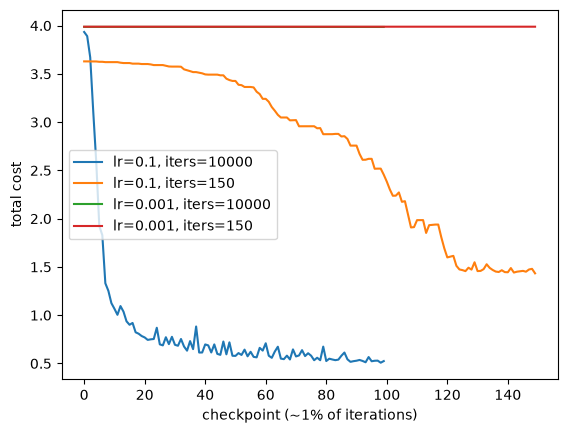

In [12]:
def train_experiment(iterations=10000, learning_rate=0.1):
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    costs = []
    checkpoint = max(1, iterations // 100)

    for i in range(iterations):
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z)
        target = point[2]

        if i % checkpoint == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz
        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

# compare learning rate / iteration combinations
configs = [
    {"iterations": 10000, "learning_rate": 0.1},
    {"iterations": 150,   "learning_rate": 0.1},
    {"iterations": 10000, "learning_rate": 0.001},
    {"iterations": 150,   "learning_rate": 0.001},
]

plt.figure()
for cfg in configs:
    exp_costs, *_ = train_experiment(**cfg)
    plt.plot(exp_costs, label=f"lr={cfg['learning_rate']}, iters={cfg['iterations']}")

plt.xlabel("checkpoint (~1% of iterations)")
plt.ylabel("total cost")
plt.legend()
plt.show()


### Exercise: modify the cost function (remove the square)

Replace $C=(\hat y - y)^2$ with $C = \hat y - y$ and observe how training behaves (cost can go negative, and gradients no longer push symmetrically toward the target).


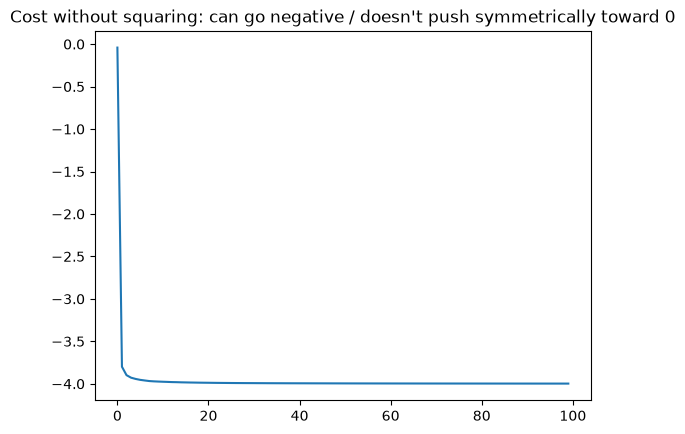

In [13]:
def train_no_square():
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    iterations = 10000
    learning_rate = 0.1
    costs = []

    for i in range(iterations):
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z)
        target = point[2]

        # cost without the square: C = pred - target (can go negative)
        cost = pred - target

        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += (p_pred - p[2])
            costs.append(c)

        # derivative of (pred - target) w.r.t. pred is just 1
        dcost_dpred = 1
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz
        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

costs_no_square, w1_ns, w2_ns, b_ns = train_no_square()
plt.figure()
plt.plot(costs_no_square)
plt.title("Cost without squaring: can go negative / doesn't push symmetrically toward 0")
plt.show()


## Part 2 — From numbers to text: sentence classification

Instead of classifying numeric flower features, we now classify short **sentences**, following the NLP preparation pipeline:

**Sentences → Tokens → Vocabulary → Numeric vectors (one-hot) → Neural network**


In [14]:
# step 1: sentence dataset, each sentence gets a binary label (0 or 1)

sentences = [
    "i love red flowers",
    "the garden is full of flowers",
    "red roses are beautiful",
    "i hate waiting in traffic",
    "the weather today is terrible",
    "this movie was boring and bad",
]

labels = [1, 1, 1, 0, 0, 0]


In [15]:
# step 2: tokenize + build vocabulary

def tokenize(sentence):
    return sentence.lower().split()

tokenized_sentences = [tokenize(s) for s in sentences]

vocab = sorted(set(word for tokens in tokenized_sentences for word in tokens))
word_to_index = {word: i for i, word in enumerate(vocab)}

print("Vocabulary:", vocab)
print("Vocabulary size:", len(vocab))


Vocabulary: ['and', 'are', 'bad', 'beautiful', 'boring', 'flowers', 'full', 'garden', 'hate', 'i', 'in', 'is', 'love', 'movie', 'of', 'red', 'roses', 'terrible', 'the', 'this', 'today', 'traffic', 'waiting', 'was', 'weather']
Vocabulary size: 25


In [16]:
# step 3: one-hot encoding (word vectors kept distinct from sentence vectors)

def word_to_onehot(word):
    # one-hot vector for a single word, shape (vocab_size,)
    vec = np.zeros(len(vocab))
    vec[word_to_index[word]] = 1
    return vec

def sentence_to_vector(tokens):
    # bag-of-words vector for a sentence: sum of its words' one-hot vectors
    vec = np.zeros(len(vocab))
    for word in tokens:
        vec += word_to_onehot(word)
    return vec

print("one-hot('flowers') =", word_to_onehot("flowers"))
print("sentence vector for", tokenized_sentences[0], "=", sentence_to_vector(tokenized_sentences[0]))


one-hot('flowers') = [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0.]
sentence vector for ['i', 'love', 'red', 'flowers'] = [0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.
 0.]


In [17]:
# step 4: matrix-based neural network (forward pass only)

# H: input matrix, one row per sentence, one column per vocabulary word
H = np.array([sentence_to_vector(tokens) for tokens in tokenized_sentences])
y_text = np.array(labels)

print("H shape (num_sentences, vocab_size):", H.shape)

vocab_size = H.shape[1]
hidden_size = 4

# randomly initialized weights, dimensions chosen so matrix multiplication is valid
W1 = np.random.randn(vocab_size, hidden_size)
b1 = np.random.randn(hidden_size)

W2 = np.random.randn(hidden_size, 1)
b2 = np.random.randn(1)

hidden = sigmoid(H @ W1 + b1)
output = sigmoid(hidden @ W2 + b2)

print("output shape:", output.shape)
print("predictions:\n", output.ravel())
print("targets:     \n", y_text)


H shape (num_sentences, vocab_size): (6, 25)
output shape: (6, 1)
predictions:
 [0.20676635 0.28026919 0.2487266  0.19732495 0.25931119 0.35181605]
targets:     
 [1 1 1 0 0 0]
